<a href="https://colab.research.google.com/github/andres-merino/FormatoBaseProyectos/blob/main/Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Carrera de Ciencia de Datos</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Asignatura &bull; Tema
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-01
            </font></p>
        </td>  
    </tr>
</table>

# Reto No. 1: Aprendizaje No Supervisado - Gestión de Residuos
**Equipo:** Grupo I

**Pregunta esencial:** ¿Qué perfiles de gestión de residuos aparecen en los registros municipales del Ecuador y cómo comunicar sus diferencias para orientar preguntas y propuestas de mejora?

**Alcance:** Análisis exploratorio de la base de datos GIRS 2024 del INEC para descubrir perfiles mediante algoritmos de agrupamiento no supervisado. No constituye un ranking de desempeño.

**Técnicas utilizadas:**
Se aplicarán K-Means y Agrupamiento Jerárquico para formar los clústeres, evaluando la calidad con el coeficiente de silueta. Posteriormente, se utilizará Análisis de Componentes Principales (PCA) estrictamente para la visualización en 2D.

Los paquetes necesarios son:

In [15]:
# Paquetes necesarios
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

---
## <font color='264CC7'> Lectura de datos </font>


Auditoría inicial de la base de datos:
Dimensiones (filas, columnas): (234, 20)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ranking_influencia         234 non-null    int64  
 1   jugador                    234 non-null    object 
 2   nacionalidad               234 non-null    object 
 3   confederacion              234 non-null    object 
 4   posicion_principal         234 non-null    object 
 5   periodo_activo_siglo_xxi   234 non-null    object 
 6   clubes_emblematicos        234 non-null    object 
 7   partidos_jugados           234 non-null    int64  
 8   minutos_jugados            234 non-null    int64  
 9   goles                      234 non-null    int64  
 10  asistencias                234 non-null    int64  
 11  contribuciones_gol_por_90  234 non-null    float64
 12  pase

,partidos_jugados,goles,asistencias,pases_clave,tarjetas_amarillas,tarjetas_rojas,titulos_colectivos
count,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000
mean,638.884615,143.974359,94.688034,791.615385,72.115385,3.068376,16.072650
std,199.872383,151.891251,71.677096,521.518587,42.662257,3.452253,9.031125
min,164.000000,0.000000,1.000000,4.000000,12.000000,0.000000,0.000000
25%,512.000000,44.000000,42.000000,407.250000,42.000000,1.000000,9.000000
50%,645.000000,88.000000,78.000000,739.000000,65.000000,2.000000,15.000000
75%,765.000000,212.000000,135.500000,1074.250000,94.000000,4.000000,21.000000
max,1343.000000,985.000000,428.000000,2972.000000,272.000000,29.000000,49.000000


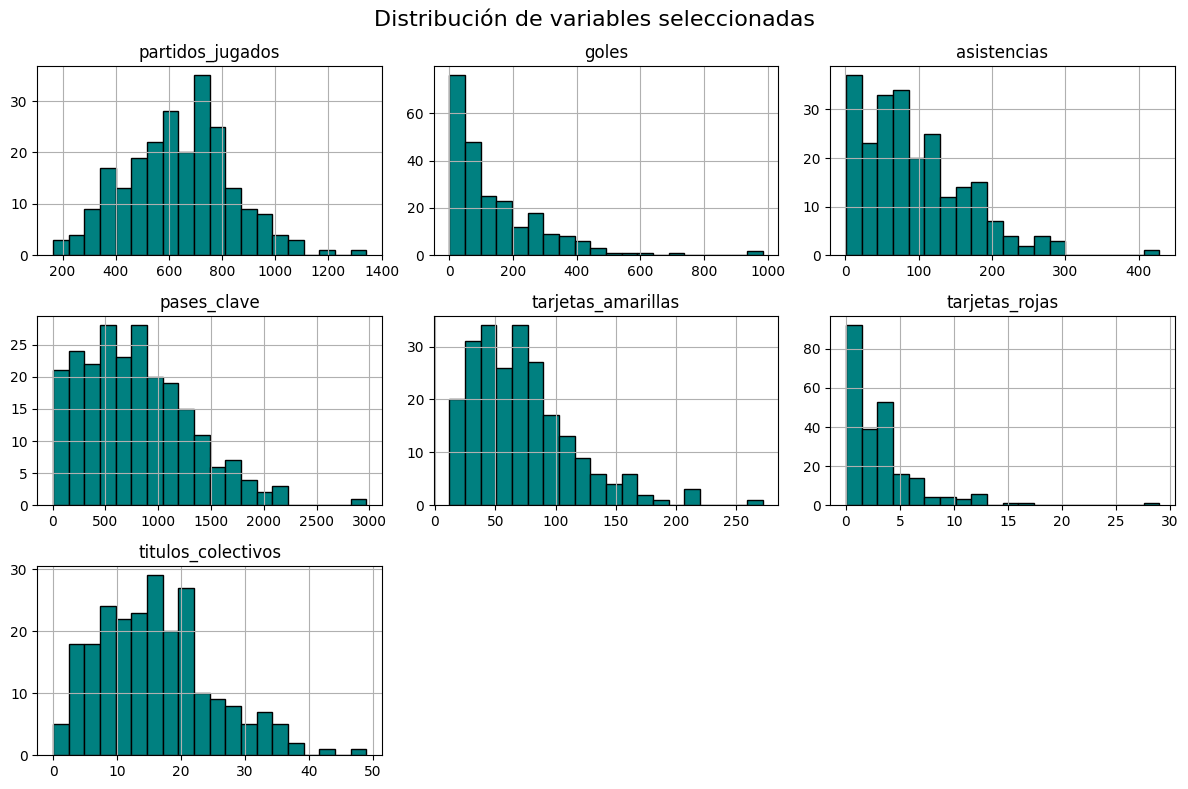

In [16]:

# Carga de datos cumpliendo las especificaciones del reto

url = 'https://raw.githubusercontent.com/juanfercaicedo/AprendizajeAutomaticoInicial/refs/heads/main/Dataset/futbollStats.csv'
df = pd.read_csv(url)

print("Auditoría inicial de la base de datos:")
print("Dimensiones (filas, columnas):", df.shape)
print("\nInformación general:")
df.info()

# Variables seleccionadas como punto de partida
features_cols = [
    'partidos_jugados',          # Volumen / longevidad
    'titulos_colectivos',        # Éxito competitivo
    'precision_pases_pct',       # Seguridad en la distribución
    'goles_por_90',              # Capacidad goleadora normalizada
    'asistencias_por_90',        # Creación de gol (evita duplicar con pases_clave_por_90, r=0.93)
    'tarjetas_amarillas_por_90', # Frecuencia disciplinaria (evita duplicar con rojas, r=0.75)
  ]
print("\nDescripción de variables seleccionadas:")
display(df[features_cols].describe())

# Representación gráfica de distribuciones
df[features_cols].hist(bins=20, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle('Distribución de variables seleccionadas', fontsize=16)
plt.tight_layout()
plt.show()

**Auditoría y Selección:**
Se verificó que la unidad de observación son los municipios. Se han elegido 5 características iniciales relacionadas con barrido, recolección y tratamiento, priorizando la cobertura de la gestión.


## <font color='264CC7'> Procesamiento de Datos </font>


In [17]:
from sklearn.preprocessing import StandardScaler

# Copia de seguridad
df_clean = df.copy()


# Escalado de datos
X = df_clean[features_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Registros conservados para el clustering: {X_scaled.shape[0]}")

Registros conservados para el clustering: 234


## <font color='264CC7'> Análisis con Clustering </font>


--- Comparación de algoritmos ---
k=2 | Silueta K-Means: 0.2858 | Silueta Jerárquico: 0.2081
k=3 | Silueta K-Means: 0.2777 | Silueta Jerárquico: 0.2407
k=4 | Silueta K-Means: 0.2741 | Silueta Jerárquico: 0.2522
k=5 | Silueta K-Means: 0.2516 | Silueta Jerárquico: 0.2241
k=6 | Silueta K-Means: 0.2172 | Silueta Jerárquico: 0.2207


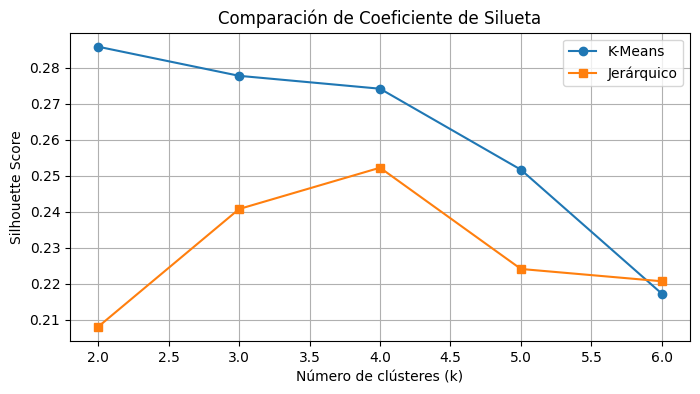


Tamaños de los grupos (K-Means):
Cluster
1    116
2     70
0     48
Name: count, dtype: int64


In [18]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

k_range = range(2, 7)
silhouette_km = []
silhouette_hc = []

print("--- Comparación de algoritmos ---")
for k in k_range:
    # K-Means con varias inicializaciones
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=15)
    labels_km = kmeans.fit_predict(X_scaled)
    sil_km = silhouette_score(X_scaled, labels_km)
    silhouette_km.append(sil_km)

    # Jerárquico (Ward, Euclidiana)
    hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels_hc = hc.fit_predict(X_scaled)
    sil_hc = silhouette_score(X_scaled, labels_hc)
    silhouette_hc.append(sil_hc)

    print(f"k={k} | Silueta K-Means: {sil_km:.4f} | Silueta Jerárquico: {sil_hc:.4f}")

# Gráfico comparativo
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_km, marker='o', label='K-Means')
plt.plot(k_range, silhouette_hc, marker='s', label='Jerárquico')
plt.title('Comparación de Coeficiente de Silueta')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True)
plt.show()

# Selección del modelo final (ajusta k_optimo según el gráfico, usualmente 3 o 4)
k_optimo = 3
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=15)
df_clean['Cluster'] = modelo_final.fit_predict(X_scaled)

print("\nTamaños de los grupos (K-Means):")
print(df_clean['Cluster'].value_counts())

## <font color='264CC7'> Reducción de Dimensiones </font>


Varianza explicada individual: [0.48753295 0.24723543]
Varianza explicada acumulada: 0.7348


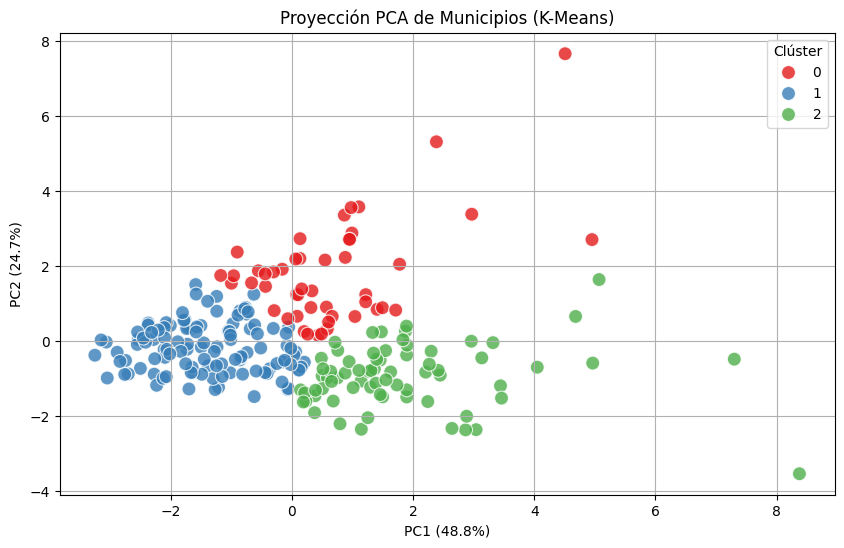


Contribución de variables a las componentes:


,partidos_jugados,goles,asistencias,pases_clave,tarjetas_amarillas,tarjetas_rojas,titulos_colectivos
PC1,0.449911,0.356863,0.44108,0.438228,0.336923,0.264781,0.316242
PC2,0.072881,-0.311711,-0.38055,-0.325781,0.526749,0.578881,0.184406


In [19]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada individual: {pca.explained_variance_ratio_}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.sum():.4f}")

# Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_clean['Cluster'], palette='Set1', s=100, alpha=0.8)
plt.title('Proyección PCA de Municipios (K-Means)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(title='Clúster')
plt.grid(True)
plt.show()

# Contribuciones
contribuciones = pd.DataFrame(pca.components_, columns=features_cols, index=['PC1', 'PC2'])
print("\nContribución de variables a las componentes:")
display(contribuciones)